# Aprendizaje de Simbolo: `ParabolicMLPSymbol` con datos GRF (laplaciano fraccionario 1D)

Mismo experimento que `02_calor_1d.ipynb` con la referencia $a(\mathbf{k})=|\mathbf{k}|^\alpha$
(`FractionalLaplacianSymbol`, $n=1$) para $\alpha\in\{0.5,\ 1,\ 1.5\}$, aprendiendo con orden $m=\alpha$
($\rho=n+1=2$ para el simbolo aprendido). Hay una seccion por $\alpha$ y, al final, una tabla resumen.

Reparametrizacion, $\kappa$ y funcion de perdida ($\mathcal{L}_{\text{traj}}$, $\mathcal{L}_{\text{par}}$,
$\mathcal{L}_{\text{class}}$): ver `02_calor_1d.ipynb`, introduccion y Setup.

# Setup
El codigo de cada seccion esta en `parabolic_symbol.learning.experiment.GRFExperiment`.

- **Datos:** GRF en $\mathbb{T}^1=[0,2\pi)$, malla de $1024$ puntos, $k_{\text{cap}} = 64$.
  Generacion y tiempos: ver `01_exploracion.ipynb`, seccion 2.1. Todos los pares $(k,t)$ con
  $|k|_\infty\le k_{\text{cap}}$, y $k_{\max}=k_{\text{cap}}$.
- **Particion, $\kappa$, $C_\alpha$, barrido, early stopping y seleccion:** como en `02_calor_1d.ipynb`
  (Setup y secciones 2 a 4), con $m=\alpha$.
- `cuda` si esta disponible y `float64`.

In [1]:
from pathlib import Path

import torch

from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.fractional_laplacian import FractionalLaplacianSymbol
from parabolic_symbol.learning.experiment import GRFExperiment, summary_table
from parabolic_symbol.utils import default_device

device = default_device()
dtype = torch.float64
print(f"device = {device}  |  dtype = {dtype}")

RESULTS = Path("../results/04_fraccionario_1d")   # tablas (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)

device = cuda  |  dtype = torch.float64


In [2]:
ALPHAS = [0.5, 1.0, 1.5]
experimentos = {
    alpha: GRFExperiment(
        reference=FractionalLaplacianSymbol(n=1, alpha=alpha), m=alpha, resolution=1024, k_cap=64,
        results=RESULTS / f"alpha_{alpha:g}", dtype=dtype, device=device,
    )
    for alpha in ALPHAS
}

# $\alpha = 0.5$

$a(\mathbf{k})=|\mathbf{k}|^{0.5}$, $m=0.5$, malla 1024 puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/04_fraccionario_1d/alpha_0.5/`.

In [3]:
exp_0_5 = experimentos[0.5]

## 1. Datos de referencia

Ventana de $k$ resultante y numero de muestras por conjunto.

In [4]:
display(exp_0_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]

k_cap = 64  ->  k_max = 64  (ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64])


,muestras,k_unicos
conjunto,,
entrenamiento,103000,103
validacion,26000,26
prueba,51600,129


## 2. $\kappa$ teorico y constantes $C_\alpha$

Banda $(c, C)$, $\kappa$ y tabla de $C_\alpha$: ver `02_calor_1d.ipynb`, seccion 2.

In [5]:
display(exp_0_5.estimate_constants())

estimate_symbol: 103,000 de 103,000 pares (k, t) con senal (tol=1e-10); 103 de 103 k de entrenamiento
  ventana usada: 103 k, |k|_inf <= 64, |k| in [0, 64]
kappa_hat referencia = 1.1892
(c, C) de los datos  = (0.7568, 1.0999)   m = 0.5, ventana: 102 k, |k|_inf <= 64, |k| in [1, 64]
kappa teorico        = 2.0000


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.499908,1.499908,103
"(1,)",1.783811,1.783811,83
"(2,)",5.045378,5.045378,69


## 3. Barrido de hiperparametros

Ejes del barrido: ver `02_calor_1d.ipynb`, seccion 3.

In [6]:
exp_0_5.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0004 |  24.7s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0004 |  22.9s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0009 |  24.1s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0009 |  22.8s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0006 |  33.7s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0006 |  33.8s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0005 |  22.9s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0005 |  22.5s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0324 |  89.8s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0347 |  81.5s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0007 |  26.6s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0007 |  26.3s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0342 |  36.2s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0342 |  36.2s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0007 |  62.7s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0007 |  62.8s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0347 |  47.5s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [7]:
barrido, por_eje = exp_0_5.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

30 corridas, 22.0 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,32,OFF,0.0001,0.000371,7.771200e-11,0.594593
1,2,32,OFF,0.0000,0.000371,7.776328e-11,0.594593
2,4,32,OFF,0.0001,0.000432,1.049912e-10,0.594775
3,4,32,OFF,0.0000,0.000432,1.050306e-10,0.594775
4,3,32,OFF,0.0001,0.000462,1.202727e-10,0.594478
5,3,32,OFF,0.0000,0.000462,1.202731e-10,0.594478
6,2,128,OFF,0.0001,0.000609,2.090688e-10,0.595049
7,2,128,OFF,0.0000,0.000609,2.090750e-10,0.595049
8,4,64,OFF,0.0000,0.000708,2.827371e-10,0.595062
9,4,64,OFF,0.0001,0.000708,2.827865e-10,0.595063


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.000371,7.771200e-11,0.594478
"ON p=0.2 capas[1,2]",6,0.014299,1.152218e-07,0.523278
ON p=0.2 capas[1],6,0.032426,5.925303e-07,0.542879


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.000371,7.776328e-11,0.523278
0.0001,15,0.000371,7.771200e-11,0.523279


### Seleccion: la mejor aproximacion

Criterio de seleccion: ver `02_calor_1d.ipynb`, seccion 4.

In [8]:
display(exp_0_5.select())

kappa = theoretical_kappa() = 2.0000
kappa_hat aprendido         = 1.1893   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 1.1892   (simbolo analitico)
arquitectura elegida    = 2 capas x 32 neuronas
dropout                 = OFF
weight decay            = 0.0001  (Linear ocultas interiores)
early stopping          = mejor epoca 15 de 45 corridas
modelo guardado en ../results/04_fraccionario_1d/alpha_0.5/modelo.pt


total                   7.771200e-11
trayectoria             7.771200e-11
parabolicidad           0.000000e+00
clase                   0.000000e+00
rel_l2                  3.713518e-04
peor ratio              5.945930e-01
puntos con ratio > 1    0.000000e+00
Name: validacion (mejor epoca), dtype: float64

### Metricas del modelo seleccionado

Reportes de trayectoria y de simbolo: ver `02_calor_1d.ipynb`, seccion 4. Aqui el simbolo se compara con $|\mathbf{k}|^{\alpha}$.

In [9]:
traj, sym = exp_0_5.metrics()
display(traj)
display(sym)

TRAYECTORIA -- muestras: 103,000 entrenamiento / 26,000 validacion; SIMBOLO -- k unicos: 103 entrenamiento / 26 validacion


,entrenamiento,validacion
mse,2.808689e-11,7.771200e-11
rmse,5.299707e-06,8.815441e-06
mae,2.139091e-06,3.618287e-06
max_error,9.969471e-05,8.846393e-05
rel_l2,2.163195e-04,3.713518e-04
r2,1.000000e+00,9.999999e-01


,entrenamiento,validacion
mse,0.000043,0.000041
rmse,0.006573,0.006379
mae,0.005973,0.005722
max_error,0.010340,0.010087
rel_l2,0.001155,0.001131


### Evaluacion en prueba

Errores en prueba: ver `02_calor_1d.ipynb`, seccion 4.

PRUEBA -- 51,600 pares (k, t), 20 condiciones iniciales nuevas
error relativo L2 (pares (k, t))        = 2.5388e-04
error relativo L2 (espacio fisico)     = 2.6913e-04  (medio; max 9.6580e-04)


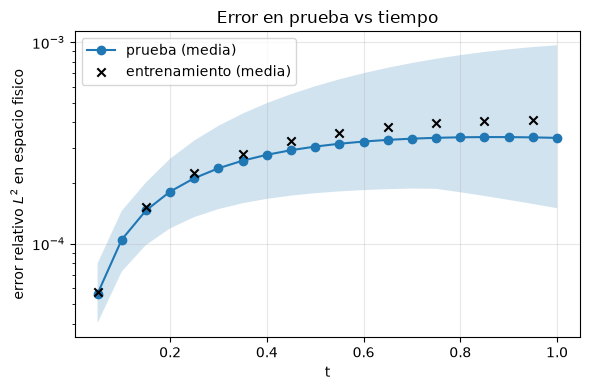

,prueba
mse,3.535272e-11
rmse,5.945816e-06
mae,2.328413e-06
max_error,1.022401e-04
rel_l2,2.538824e-04
r2,9.999999e-01
rel_l2_fisico_medio,2.691324e-04
rel_l2_fisico_max,9.658012e-04


In [10]:
display(exp_0_5.test())

## 5. Curvas de entrenamiento

Perdida y criterio de early stopping: ver `02_calor_1d.ipynb`, seccion 5.

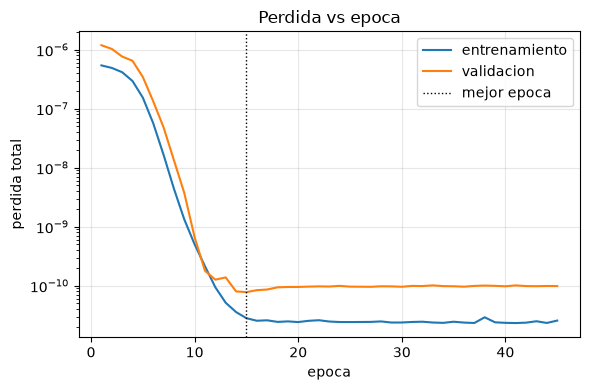

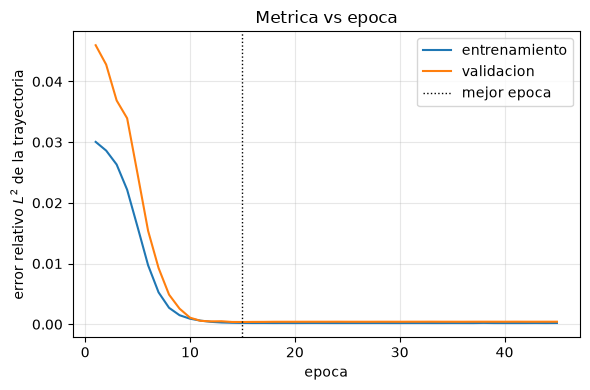

In [11]:
exp_0_5.curves()

## 6. Simbolo aprendido vs. referencia

Simbolo frente a $|\mathbf{k}|^{0.5}$ en $|k_i|\le k_{\max}$: curva contra $|k|$, paridad y error absoluto contra $k$.

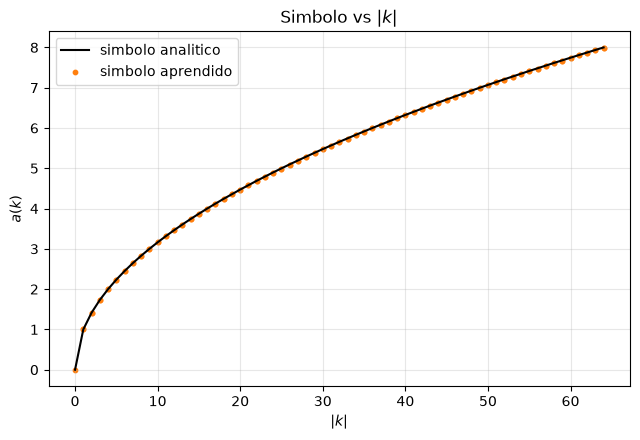

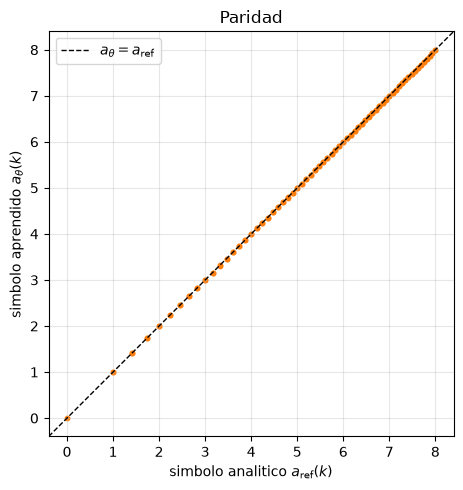

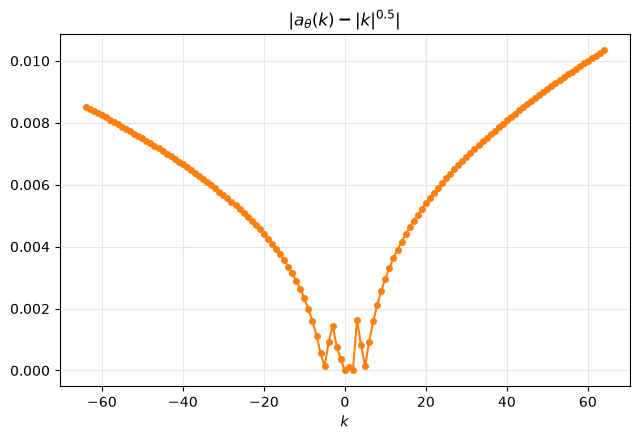

error relativo medio = 0.001, maximo = 0.001  (|k_i| <= 64, k = 0 excluido del cociente)


In [12]:
exp_0_5.symbol_figure()

## 7. Certificacion de parabolicidad

Rejilla de certificacion: ver `02_calor_1d.ipynb`, seccion 7.

In [13]:
display(exp_0_5.certification())

ParabolicMLPSymbol(c=0.7568, C=1.1, hidden=(32, 32), sin dropout)(n=1, m=0.5, rho=2, dim=1)
kappa usada = 2.0000
rejilla de certificacion: |k_i| <= K x 625 lambda (|lambda| en [1e-2, 1e3], Re(lambda) >= 0)
kappa minimo que certificaria |k_i| <= 192: 1.1893


,K,region,puntos,max_ratio,satisfecha
0,64,dentro,80625,0.594649,True
1,128,fuera,160625,0.594649,True
2,192,fuera,240625,0.594649,True


## 8. Clase del simbolo: $S^{m,\rho}$

Verificacion de la clase: ver `01_exploracion.ipynb`, seccion 5, y `02_calor_1d.ipynb`, seccion 8.

In [14]:
display(exp_0_5.symbol_class())

consistentes: 3 de 3 multiindices (rho = 2, m = 0.5)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.985411,0.995571,0.997437,0.998913,1.001479,0.500053,0.5,True,True
1,"(1,)",1,1.189646,1.189646,1.189646,1.189646,1.000000,-0.502815,-0.5,True,True
2,"(2,)",2,3.363993,3.363993,3.363993,3.363993,1.000000,-1.516857,-1.5,True,True


## 9. Resultados (desde `modelo.pt`)

Carga `modelo.pt` (guardado por `select`), reconstruye el simbolo y regenera los datos; se puede ejecutar sola, despues del Setup, sin volver a entrenar. Si no hay `modelo.pt`, la primera celda reentrena solo la configuracion elegida (de `seleccion.csv`). Como leer cada figura: ver `02_calor_1d.ipynb`, seccion 9.

In [15]:
from parabolic_symbol.learning import figures
from parabolic_symbol.learning.experiment import GRFExperiment, load_experiment_model

device = exp_0_5.device
if not (exp_0_5.results / "modelo.pt").exists():
    exp_0_5.retrain_selected()   # solo la configuracion elegida, sin barrido

In [16]:
cargado = GRFExperiment.from_checkpoint(exp_0_5.results / "modelo.pt", device=device)   # configuracion guardada en modelo.pt
modelo = load_experiment_model(exp_0_5.results / "modelo.pt", device=device)
cargado.regenerate_data()   # entrenamiento, validacion y prueba: misma semilla, mismos datos

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]


**Campo.** Primera condicion inicial de prueba: solucion exacta, la del simbolo aprendido y su diferencia.

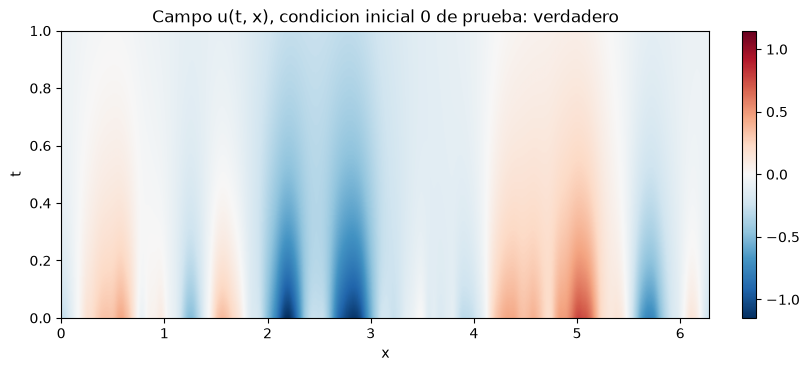

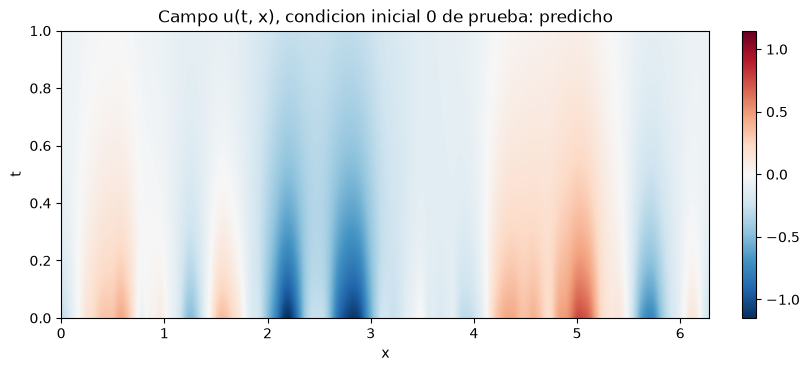

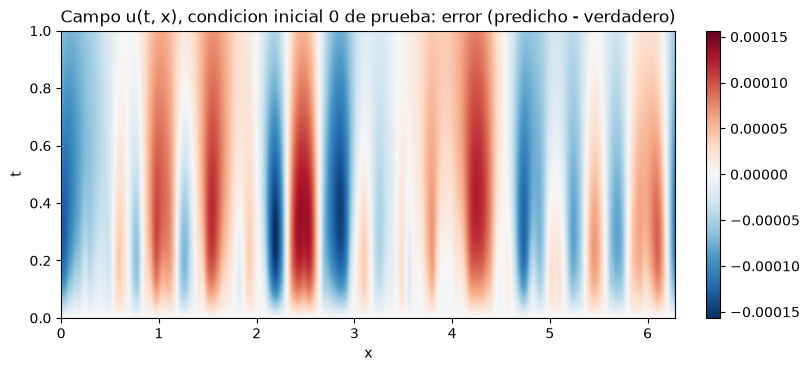

In [17]:
figures.field_figure(modelo, cargado.grf_test, cargado.results)

**Multiplicador.** $e^{-t a_\theta(k)}$, $e^{-t a(k)}$ y su diferencia sobre $(k,t)$ en la ventana de entrenamiento.

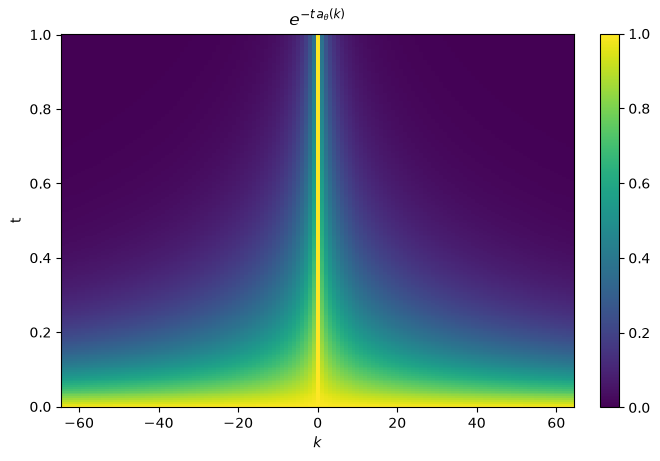

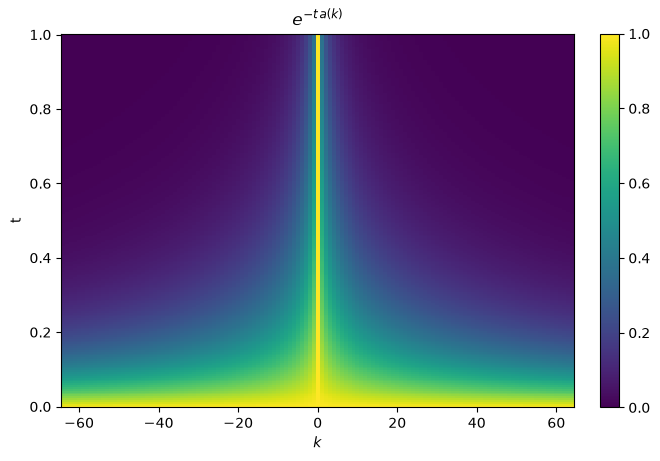

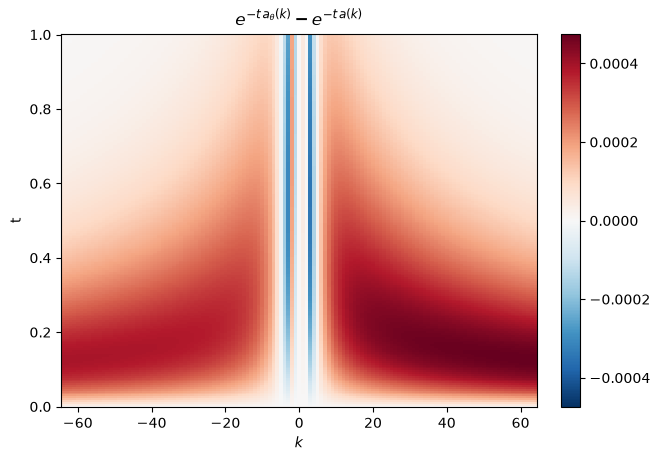

In [18]:
figures.multiplier_figure(modelo, cargado.reference, cargado.results, K=cargado.k_max)

**Simbolo fuera de la ventana.** $a_\theta(k)$ frente a la referencia hasta $|k|=1000$, y $h_\theta(k)=a_\theta(k)/\langle k\rangle^m$ con la banda $(c,C)$.

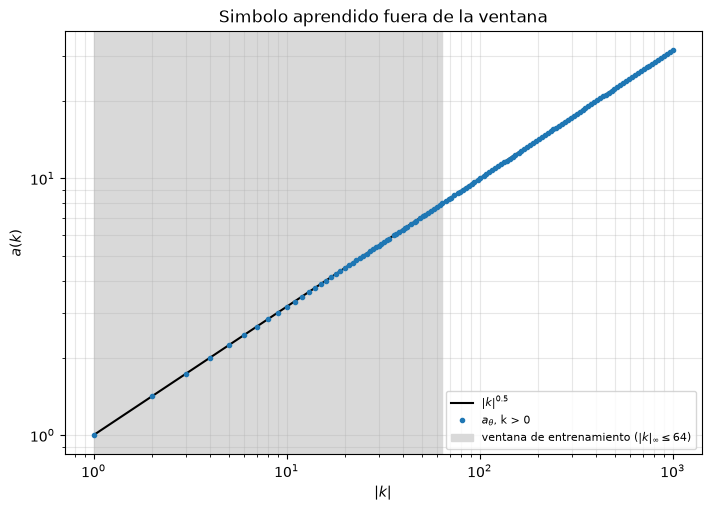

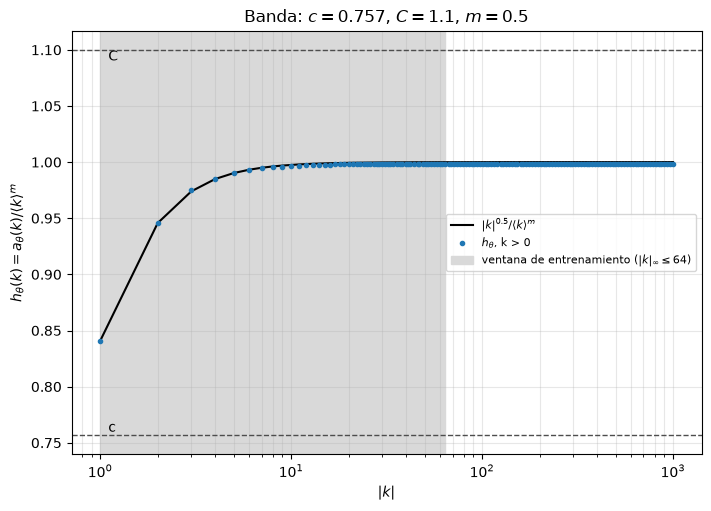

In [19]:
figures.symbol_extrapolation_figure(modelo, cargado.reference, cargado.results, k_window=cargado.k_max)

**Error contra $t$, con extrapolacion.** Error relativo $L^2$ en espacio fisico de las condiciones iniciales de prueba, hasta $t=3$.

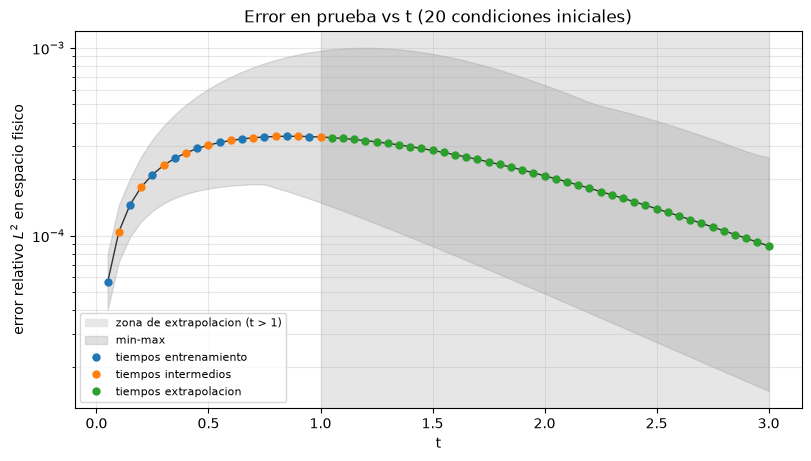

In [20]:
figures.extrapolation_error_figure(modelo, cargado.grf_test, cargado.results)

**Error del simbolo.** $|a_\theta(k)-a(k)|/|a(k)|$ en cada $k$ de entrenamiento y de validacion.

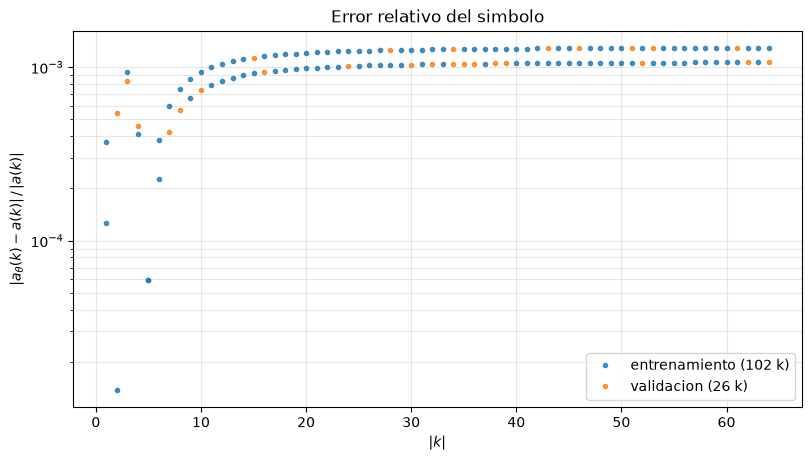

In [21]:
figures.symbol_error_figure(modelo, cargado.reference, cargado.train_data, cargado.val_data, cargado.results)

**Espectro de potencia.** $\mathbb{E}|\hat u(t,k)|^2$ medio de las condiciones iniciales de prueba, por capa de $|k|$, en $t\in\{0.05,0.25,1\}$.

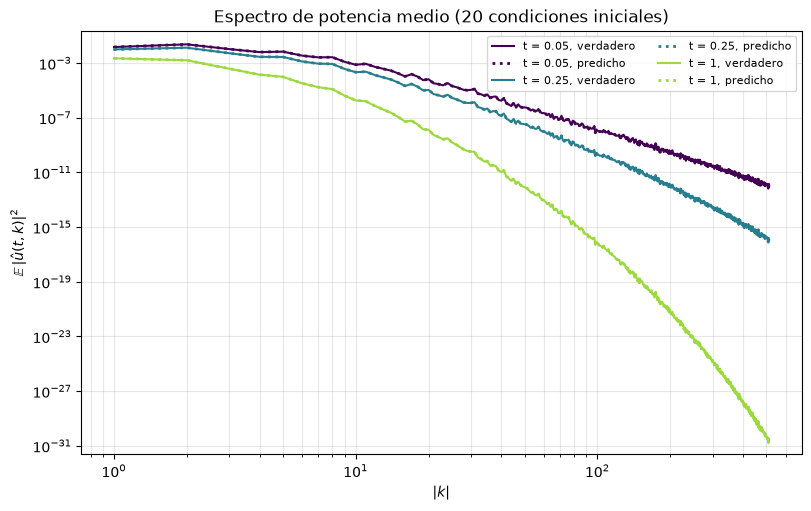

In [22]:
figures.power_spectrum_figure(modelo, cargado.grf_test, cargado.results)

# $\alpha = 1$

$a(\mathbf{k})=|\mathbf{k}|^{1}$, $m=1$, malla 1024 puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/04_fraccionario_1d/alpha_1/`.

In [23]:
exp_1_0 = experimentos[1.0]

## 1. Datos de referencia

In [24]:
display(exp_1_0.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]

k_cap = 64  ->  k_max = 64  (ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64])


,muestras,k_unicos
conjunto,,
entrenamiento,103000,103
validacion,26000,26
prueba,51600,129


## 2. $\kappa$ teorico y constantes $C_\alpha$

In [25]:
display(exp_1_0.estimate_constants())

estimate_symbol: 75,100 de 103,000 pares (k, t) con senal (tol=1e-10); 103 de 103 k de entrenamiento
  ventana usada: 103 k, |k|_inf <= 64, |k| in [0, 64]
kappa_hat referencia = 1.4142
(c, C) de los datos  = (0.6364, 1.0999)   m = 1, ventana: 102 k, |k|_inf <= 64, |k| in [1, 64]
kappa teorico        = 2.2222


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.499817,1.499817,103
"(1,)",1.500000,1.500000,83
"(2,)",4.242641,4.242641,69


## 3. Barrido de hiperparametros

In [26]:
exp_1_0.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0016 |  23.1s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0016 |  22.4s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0013 |  21.4s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0013 |  22.1s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0012 |  34.2s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0012 |  34.3s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0033 |  20.6s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0033 |  21.4s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0725 |  17.5s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0725 |  17.8s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0023 |  22.2s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0023 |  22.1s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0643 |  23.5s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0646 |  20.4s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0011 |  59.5s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0011 |  59.5s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0650 |  47.1s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [27]:
barrido, por_eje = exp_1_0.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

30 corridas, 20.7 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,3,128,OFF,0.0000,0.001128,4.331123e-10,0.636121
1,3,128,OFF,0.0001,0.001128,4.331154e-10,0.636120
2,2,128,OFF,0.0000,0.001208,4.965626e-10,0.637872
3,2,128,OFF,0.0001,0.001208,4.967665e-10,0.637872
4,2,64,OFF,0.0001,0.001287,5.632244e-10,0.638174
5,2,64,OFF,0.0000,0.001287,5.632739e-10,0.638174
6,2,32,OFF,0.0001,0.001634,9.083246e-10,0.637353
7,2,32,OFF,0.0000,0.001635,9.095119e-10,0.637354
8,3,64,OFF,0.0001,0.002324,1.837474e-09,0.637552
9,3,64,OFF,0.0000,0.002325,1.839504e-09,0.637552


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.001128,4.331123e-10,0.636120
"ON p=0.2 capas[1,2]",6,0.025141,2.150211e-07,0.510756
ON p=0.2 capas[1],6,0.064326,1.407705e-06,0.527075


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.001128,4.331123e-10,0.510756
0.0001,15,0.001128,4.331154e-10,0.510756


### Seleccion: la mejor aproximacion

In [28]:
display(exp_1_0.select())

kappa = theoretical_kappa() = 2.2222
kappa_hat aprendido         = 1.4137   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 1.4142   (simbolo analitico)
arquitectura elegida    = 3 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 8 de 38 corridas
modelo guardado en ../results/04_fraccionario_1d/alpha_1/modelo.pt


total                   4.331123e-10
trayectoria             4.331123e-10
parabolicidad           0.000000e+00
clase                   0.000000e+00
rel_l2                  1.128324e-03
peor ratio              6.361208e-01
puntos con ratio > 1    0.000000e+00
Name: validacion (mejor epoca), dtype: float64

### Metricas del modelo seleccionado

In [29]:
traj, sym = exp_1_0.metrics()
display(traj)
display(sym)

TRAYECTORIA -- muestras: 103,000 entrenamiento / 26,000 validacion; SIMBOLO -- k unicos: 103 entrenamiento / 26 validacion


,entrenamiento,validacion
mse,1.022147e-08,4.331123e-10
rmse,1.011013e-04,2.081135e-05
mae,1.765012e-05,7.442507e-06
max_error,2.188606e-03,2.166927e-04
rel_l2,4.517321e-03,1.128324e-03
r2,9.999796e-01,9.999987e-01


,entrenamiento,validacion
mse,0.040248,0.042996
rmse,0.200620,0.207354
mae,0.164851,0.171388
max_error,0.421344,0.428100
rel_l2,0.005378,0.005608


### Evaluacion en prueba

PRUEBA -- 51,600 pares (k, t), 20 condiciones iniciales nuevas
error relativo L2 (pares (k, t))        = 4.9921e-03
error relativo L2 (espacio fisico)     = 3.8852e-03  (medio; max 1.4214e-02)


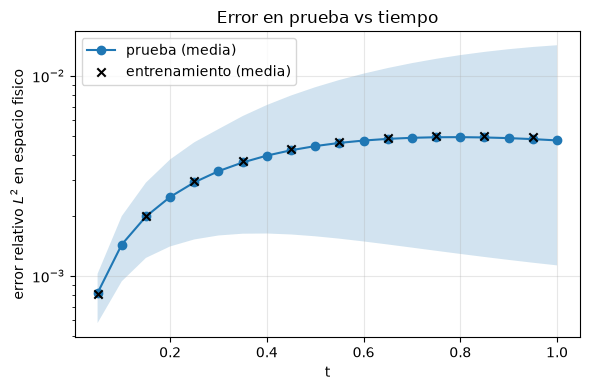

,prueba
mse,1.067178e-08
rmse,1.033043e-04
mae,1.548940e-05
max_error,2.323113e-03
rel_l2,4.992119e-03
r2,9.999750e-01
rel_l2_fisico_medio,3.885150e-03
rel_l2_fisico_max,1.421402e-02


In [30]:
display(exp_1_0.test())

## 5. Curvas de entrenamiento

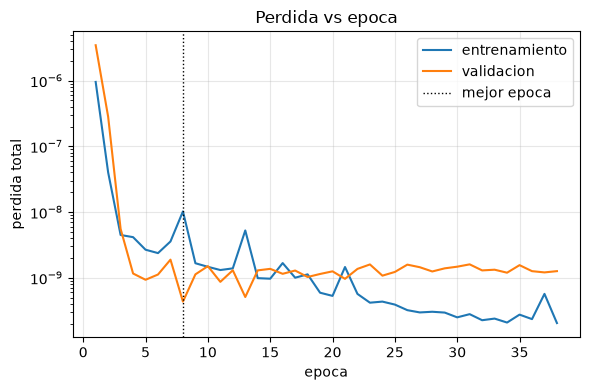

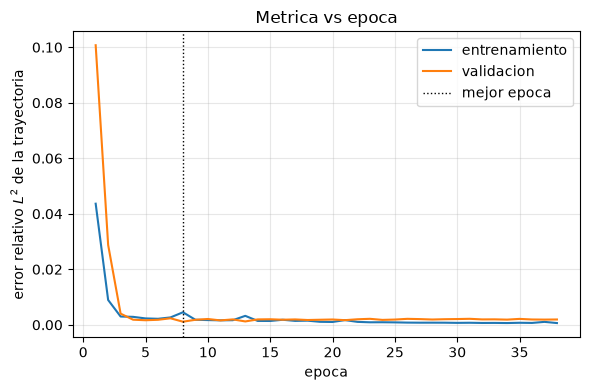

In [31]:
exp_1_0.curves()

## 6. Simbolo aprendido vs. referencia

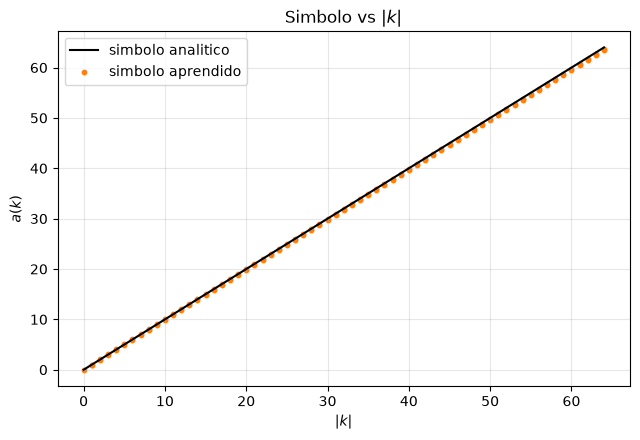

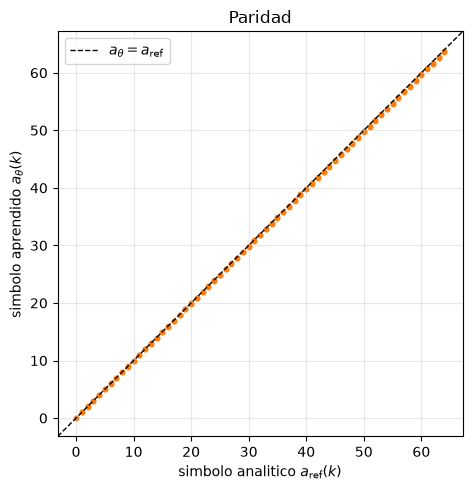

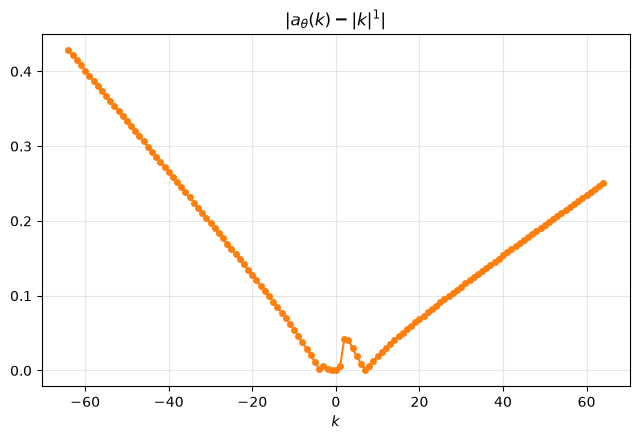

error relativo medio = 0.005, maximo = 0.021  (|k_i| <= 64, k = 0 excluido del cociente)


In [32]:
exp_1_0.symbol_figure()

## 7. Certificacion de parabolicidad

In [33]:
display(exp_1_0.certification())

ParabolicMLPSymbol(c=0.6364, C=1.1, hidden=(128, 128, 128), sin dropout)(n=1, m=1.0, rho=2, dim=1)
kappa usada = 2.2222
rejilla de certificacion: |k_i| <= K x 625 lambda (|lambda| en [1e-2, 1e3], Re(lambda) >= 0)
kappa minimo que certificaria |k_i| <= 192: 1.4137


,K,region,puntos,max_ratio,satisfecha
0,64,dentro,80625,0.636159,True
1,128,fuera,160625,0.636159,True
2,192,fuera,240625,0.636159,True


## 8. Clase del simbolo: $S^{m,\rho}$

In [34]:
display(exp_1_0.symbol_class())

consistentes: 3 de 3 multiindices (rho = 2, m = 1)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.977320,0.991513,0.994032,0.996003,1.001984,1.000071,1.0,True,True
1,"(1,)",1,1.036059,1.036059,1.036059,1.036059,1.000000,0.000052,0.0,True,True
2,"(2,)",2,2.836667,2.836667,2.836667,2.836667,1.000000,-2.964468,-1.0,True,True


## 9. Resultados (desde `modelo.pt`)

In [35]:
from parabolic_symbol.learning import figures
from parabolic_symbol.learning.experiment import GRFExperiment, load_experiment_model

device = exp_1_0.device
if not (exp_1_0.results / "modelo.pt").exists():
    exp_1_0.retrain_selected()   # solo la configuracion elegida, sin barrido

In [36]:
cargado = GRFExperiment.from_checkpoint(exp_1_0.results / "modelo.pt", device=device)   # configuracion guardada en modelo.pt
modelo = load_experiment_model(exp_1_0.results / "modelo.pt", device=device)
cargado.regenerate_data()   # entrenamiento, validacion y prueba: misma semilla, mismos datos

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]


**Campo.** Primera condicion inicial de prueba: solucion exacta, la del simbolo aprendido y su diferencia.

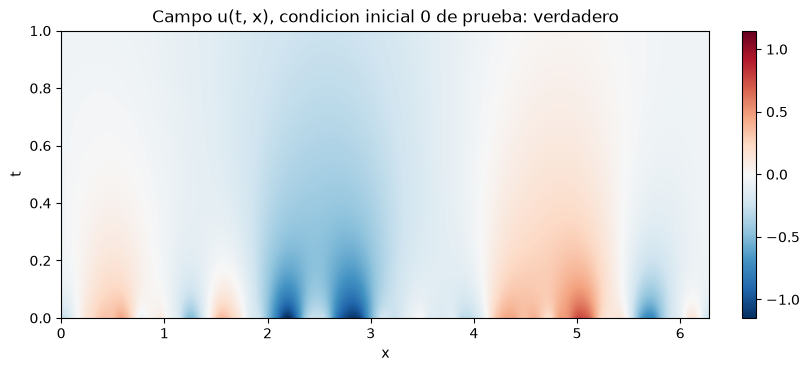

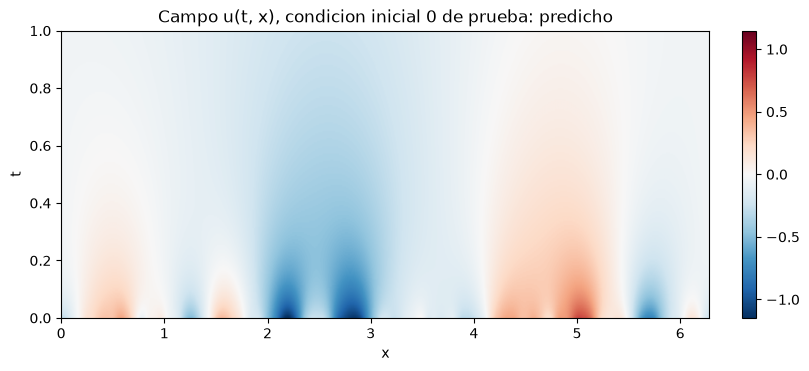

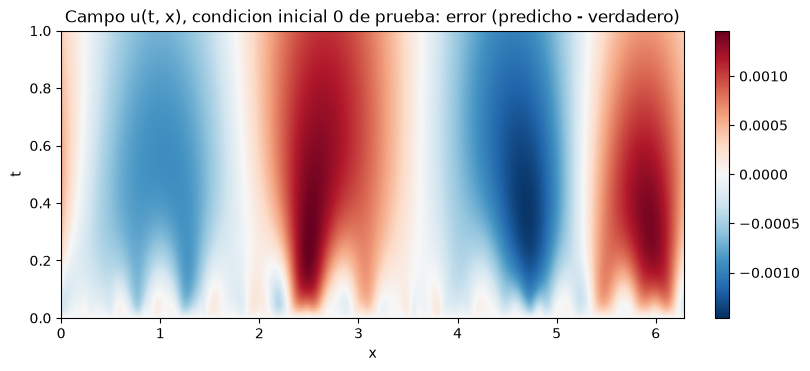

In [37]:
figures.field_figure(modelo, cargado.grf_test, cargado.results)

**Multiplicador.** $e^{-t a_\theta(k)}$, $e^{-t a(k)}$ y su diferencia sobre $(k,t)$ en la ventana de entrenamiento.

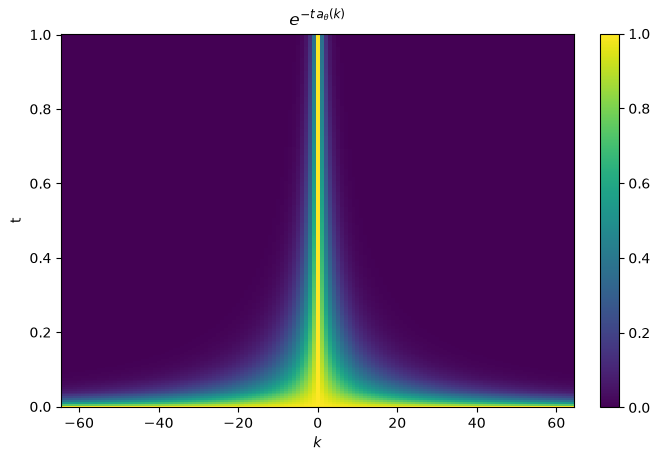

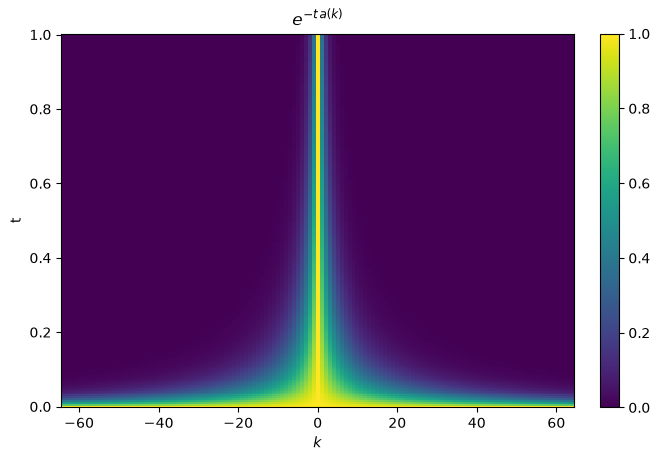

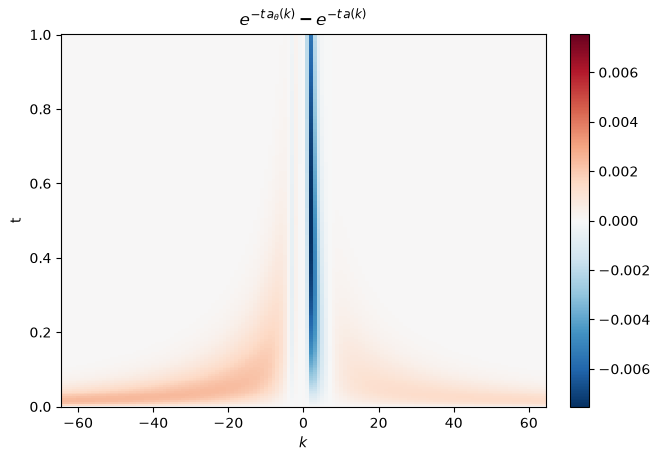

In [38]:
figures.multiplier_figure(modelo, cargado.reference, cargado.results, K=cargado.k_max)

**Simbolo fuera de la ventana.** $a_\theta(k)$ frente a la referencia hasta $|k|=1000$, y $h_\theta(k)=a_\theta(k)/\langle k\rangle^m$ con la banda $(c,C)$.

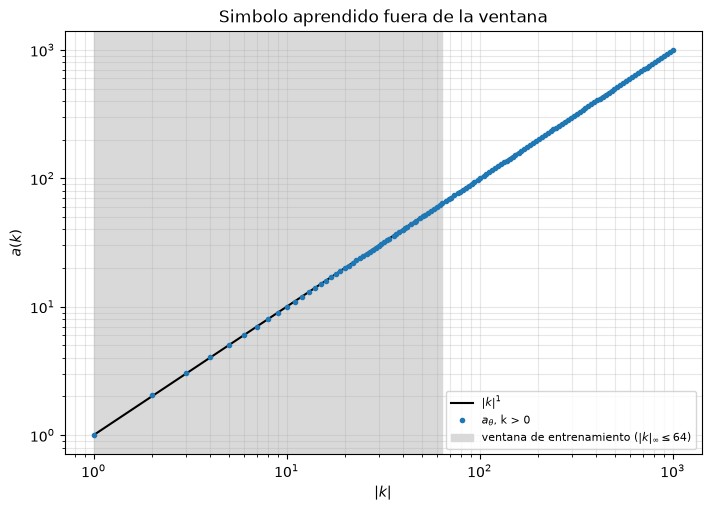

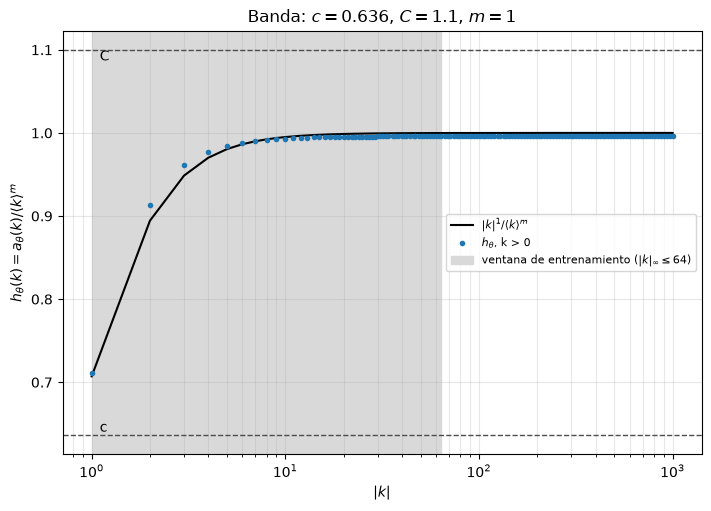

In [39]:
figures.symbol_extrapolation_figure(modelo, cargado.reference, cargado.results, k_window=cargado.k_max)

**Error contra $t$, con extrapolacion.** Error relativo $L^2$ en espacio fisico de las condiciones iniciales de prueba, hasta $t=3$.

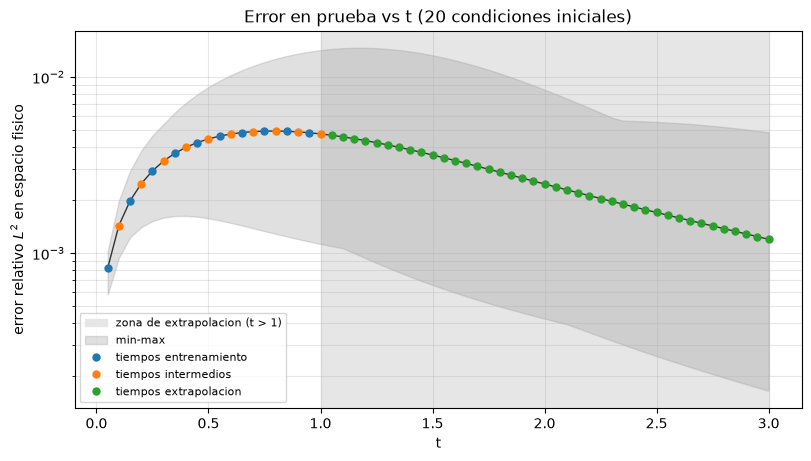

In [40]:
figures.extrapolation_error_figure(modelo, cargado.grf_test, cargado.results)

**Error del simbolo.** $|a_\theta(k)-a(k)|/|a(k)|$ en cada $k$ de entrenamiento y de validacion.

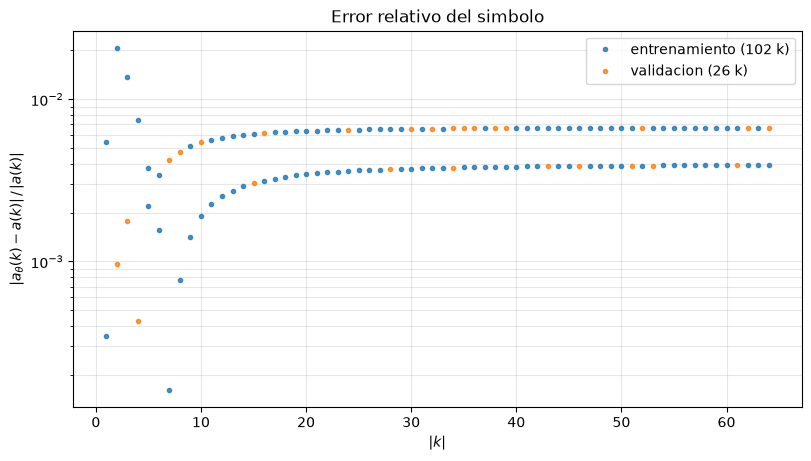

In [41]:
figures.symbol_error_figure(modelo, cargado.reference, cargado.train_data, cargado.val_data, cargado.results)

**Espectro de potencia.** $\mathbb{E}|\hat u(t,k)|^2$ medio de las condiciones iniciales de prueba, por capa de $|k|$, en $t\in\{0.05,0.25,1\}$.

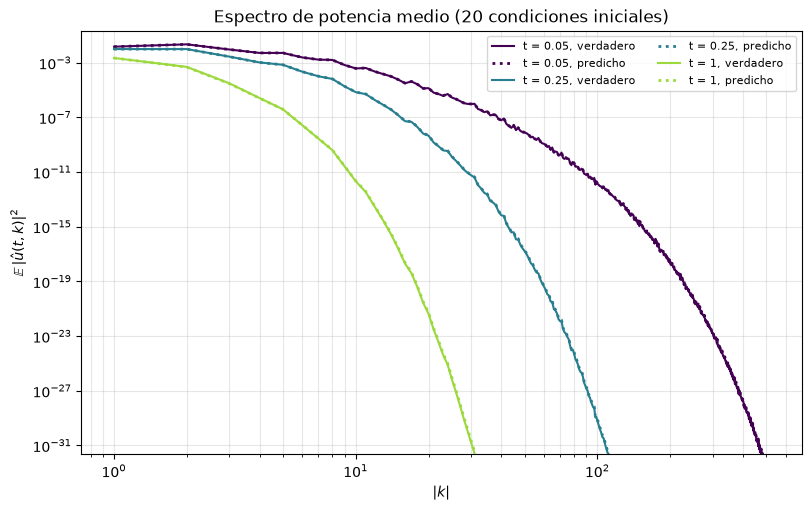

In [42]:
figures.power_spectrum_figure(modelo, cargado.grf_test, cargado.results)

# $\alpha = 1.5$

$a(\mathbf{k})=|\mathbf{k}|^{1.5}$, $m=1.5$, malla 1024 puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/04_fraccionario_1d/alpha_1.5/`.

In [43]:
exp_1_5 = experimentos[1.5]

## 1. Datos de referencia

In [44]:
display(exp_1_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]

k_cap = 64  ->  k_max = 64  (ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64])


,muestras,k_unicos
conjunto,,
entrenamiento,103000,103
validacion,26000,26
prueba,51600,129


## 2. $\kappa$ teorico y constantes $C_\alpha$

In [45]:
display(exp_1_5.estimate_constants())

estimate_symbol: 29,600 de 103,000 pares (k, t) con senal (tol=1e-10); 96 de 103 k de entrenamiento
  ventana usada: 96 k, |k|_inf <= 59, |k| in [0, 59]
kappa_hat referencia = 1.6818
(c, C) de los datos  = (0.5351, 1.0998)   m = 1.5, ventana: 95 k, |k|_inf <= 59, |k| in [1, 59]
kappa teorico        = 2.6427


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.499677,1.499725,96
"(1,)",2.375090,2.375090,78
"(2,)",3.567621,3.567621,65


## 3. Barrido de hiperparametros

In [46]:
exp_1_5.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0037 |  30.6s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0037 |  26.5s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0023 |  29.2s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0023 |  27.9s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0022 |  39.3s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0022 |  39.1s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0084 |  24.3s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0084 |  25.1s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0982 |  20.1s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0981 |  20.1s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0055 |  23.8s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0055 |  23.6s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0873 |  20.2s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0873 |  20.1s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0060 |  55.6s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0060 |  55.1s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0911 |  47.7s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [47]:
barrido, por_eje = exp_1_5.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

30 corridas, 18.0 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,128,OFF,0.0000,0.002231,1.017699e-09,0.654331
1,2,128,OFF,0.0001,0.002231,1.017823e-09,0.654331
2,2,64,OFF,0.0000,0.002332,1.112560e-09,0.656547
3,2,64,OFF,0.0001,0.002333,1.112928e-09,0.656547
4,2,32,OFF,0.0000,0.003689,2.782888e-09,0.657135
5,2,32,OFF,0.0001,0.003691,2.785949e-09,0.657134
6,3,64,OFF,0.0001,0.005509,6.208200e-09,0.658917
7,3,64,OFF,0.0000,0.005510,6.210453e-09,0.658917
8,3,128,OFF,0.0001,0.005992,7.344102e-09,0.657822
9,3,128,OFF,0.0000,0.005995,7.351503e-09,0.657824


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.002231,1.017699e-09,0.654331
"ON p=0.2 capas[1,2]",6,0.041713,3.558629e-07,0.496483
ON p=0.2 capas[1],6,0.087308,1.559057e-06,0.515792


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.002231,1.017699e-09,0.496483
0.0001,15,0.002231,1.017823e-09,0.496483


### Seleccion: la mejor aproximacion

In [48]:
display(exp_1_5.select())

kappa = theoretical_kappa() = 2.6427
kappa_hat aprendido         = 1.7272   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 1.6818   (simbolo analitico)
arquitectura elegida    = 2 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 11 de 41 corridas
modelo guardado en ../results/04_fraccionario_1d/alpha_1.5/modelo.pt


total                   1.017699e-09
trayectoria             1.017699e-09
parabolicidad           0.000000e+00
clase                   0.000000e+00
rel_l2                  2.230668e-03
peor ratio              6.543307e-01
puntos con ratio > 1    0.000000e+00
Name: validacion (mejor epoca), dtype: float64

### Metricas del modelo seleccionado

In [49]:
traj, sym = exp_1_5.metrics()
display(traj)
display(sym)

TRAYECTORIA -- muestras: 103,000 entrenamiento / 26,000 validacion; SIMBOLO -- k unicos: 103 entrenamiento / 26 validacion


,entrenamiento,validacion
mse,4.329735e-09,1.017699e-09
rmse,6.580072e-05,3.190139e-05
mae,1.211635e-05,7.653892e-06
max_error,1.531667e-03,5.560361e-04
rel_l2,3.106723e-03,2.230668e-03
r2,9.999903e-01,9.999950e-01


,entrenamiento,validacion
mse,22.026584,20.868649
rmse,4.693249,4.568222
mae,3.713296,3.573718
max_error,10.176910,9.465750
rel_l2,0.018082,0.017794


### Evaluacion en prueba

PRUEBA -- 51,600 pares (k, t), 20 condiciones iniciales nuevas


error relativo L2 (pares (k, t))        = 3.5359e-03
error relativo L2 (espacio fisico)     = 2.8129e-03  (medio; max 9.0680e-03)


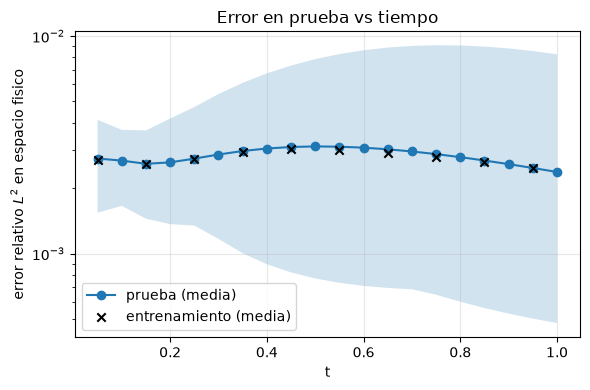

,prueba
mse,4.525858e-09
rmse,6.727450e-05
mae,1.048026e-05
max_error,1.618783e-03
rel_l2,3.535949e-03
r2,9.999875e-01
rel_l2_fisico_medio,2.812855e-03
rel_l2_fisico_max,9.067993e-03


In [50]:
display(exp_1_5.test())

## 5. Curvas de entrenamiento

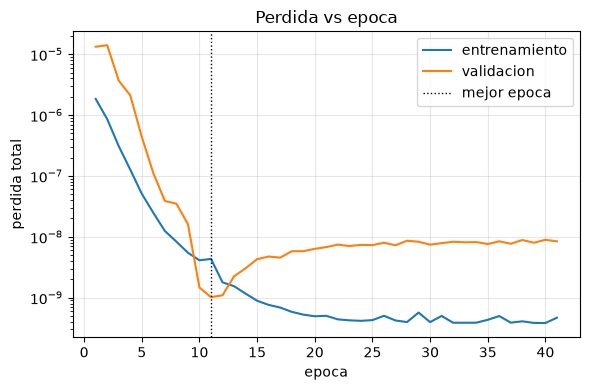

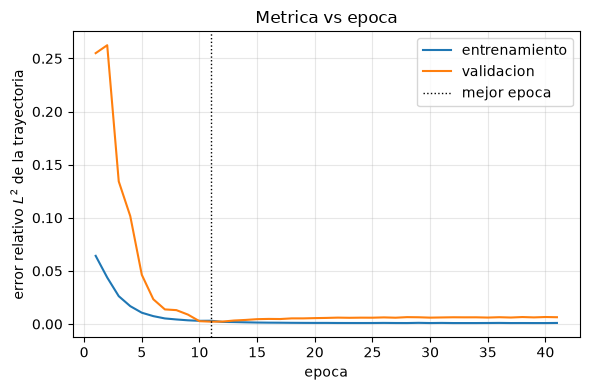

In [51]:
exp_1_5.curves()

## 6. Simbolo aprendido vs. referencia

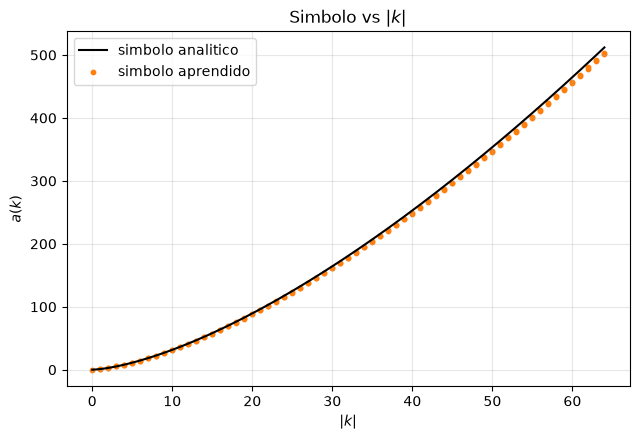

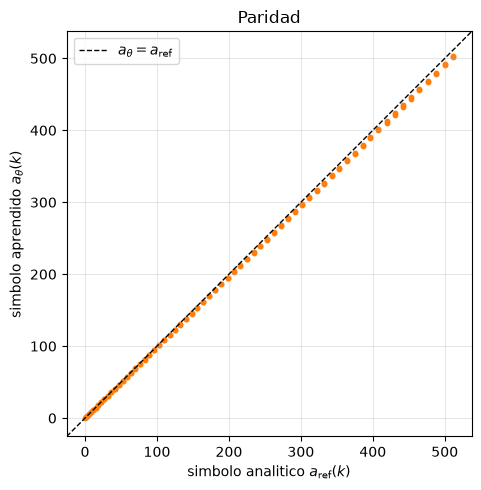

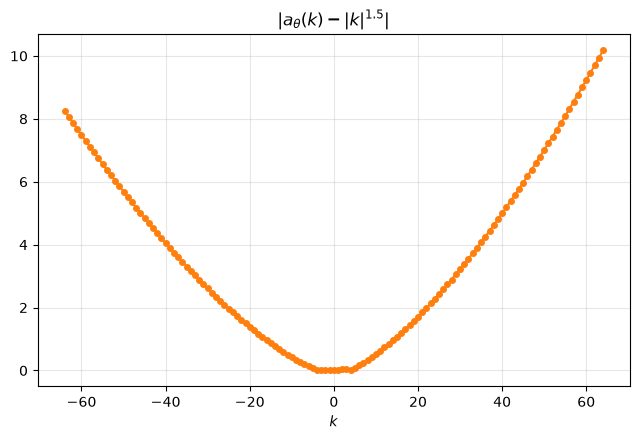

error relativo medio = 0.016, maximo = 0.020  (|k_i| <= 64, k = 0 excluido del cociente)


In [52]:
exp_1_5.symbol_figure()

## 7. Certificacion de parabolicidad

In [53]:
display(exp_1_5.certification())

ParabolicMLPSymbol(c=0.5351, C=1.1, hidden=(128, 128), sin dropout)(n=1, m=1.5, rho=2, dim=1)
kappa usada = 2.6427
rejilla de certificacion: |k_i| <= K x 625 lambda (|lambda| en [1e-2, 1e3], Re(lambda) >= 0)
kappa minimo que certificaria |k_i| <= 192: 1.7272


,K,region,puntos,max_ratio,satisfecha
0,64,dentro,80625,0.65358,True
1,128,fuera,160625,0.65358,True
2,192,fuera,240625,0.65358,True


## 8. Clase del simbolo: $S^{m,\rho}$

In [54]:
display(exp_1_5.symbol_class())

consistentes: 3 de 3 multiindices (rho = 2, m = 1.5)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.953854,0.976558,0.980619,0.983780,1.003223,1.500115,1.5,True,True
1,"(1,)",1,1.582713,1.582713,1.582713,1.582713,1.000000,0.497353,0.5,True,True
2,"(2,)",2,2.383425,2.383425,2.383425,2.383425,1.000000,-0.505727,-0.5,True,True


## 9. Resultados (desde `modelo.pt`)

In [55]:
from parabolic_symbol.learning import figures
from parabolic_symbol.learning.experiment import GRFExperiment, load_experiment_model

device = exp_1_5.device
if not (exp_1_5.results / "modelo.pt").exists():
    exp_1_5.retrain_selected()   # solo la configuracion elegida, sin barrido

In [56]:
cargado = GRFExperiment.from_checkpoint(exp_1_5.results / "modelo.pt", device=device)   # configuracion guardada en modelo.pt
modelo = load_experiment_model(exp_1_5.results / "modelo.pt", device=device)
cargado.regenerate_data()   # entrenamiento, validacion y prueba: misma semilla, mismos datos

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]


**Campo.** Primera condicion inicial de prueba: solucion exacta, la del simbolo aprendido y su diferencia.

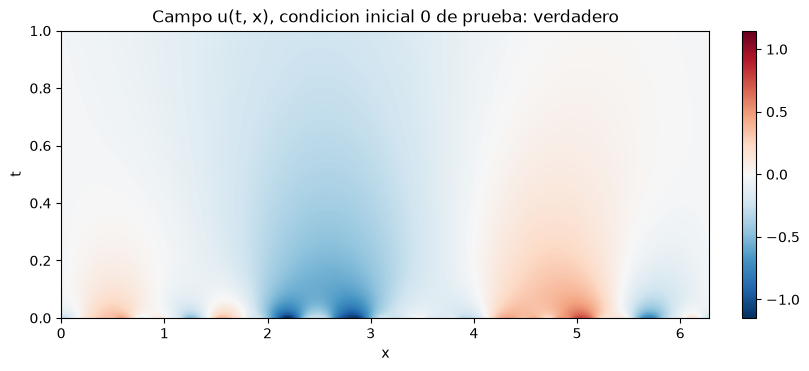

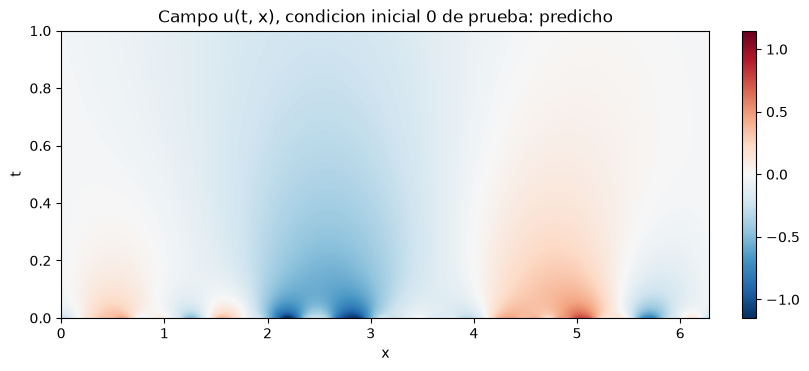

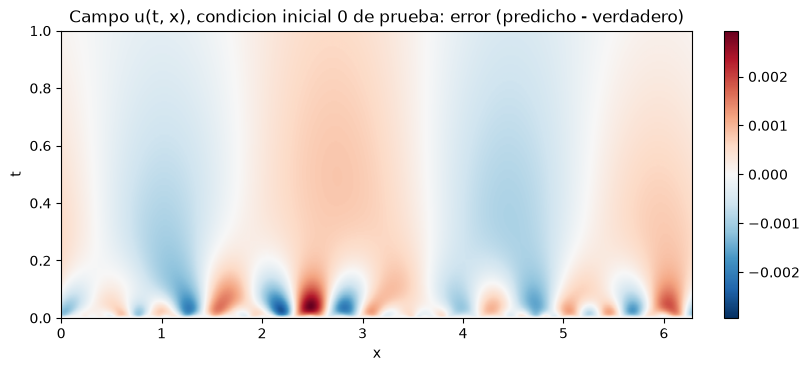

In [57]:
figures.field_figure(modelo, cargado.grf_test, cargado.results)

**Multiplicador.** $e^{-t a_\theta(k)}$, $e^{-t a(k)}$ y su diferencia sobre $(k,t)$ en la ventana de entrenamiento.

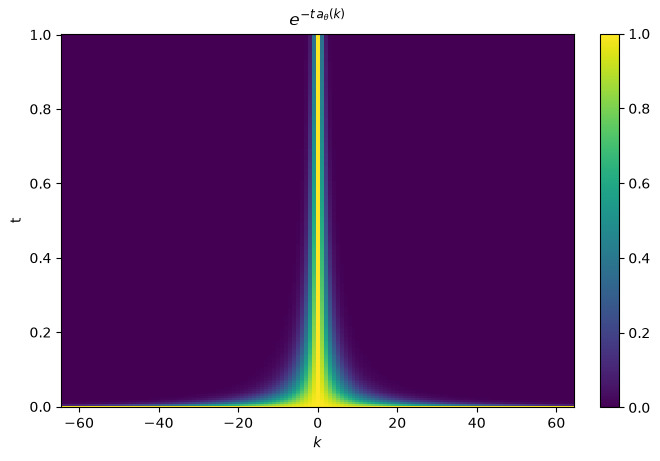

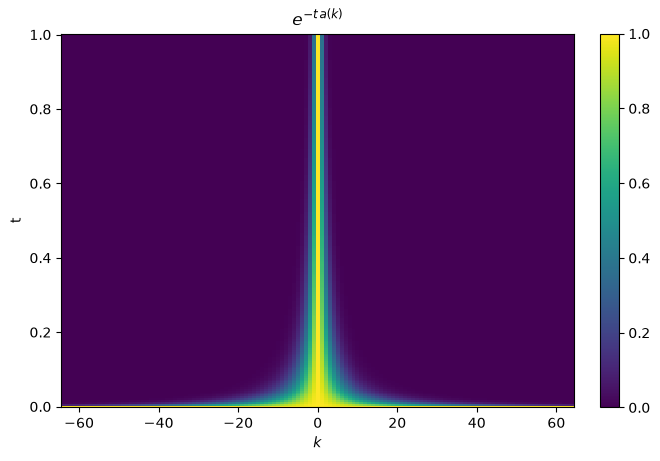

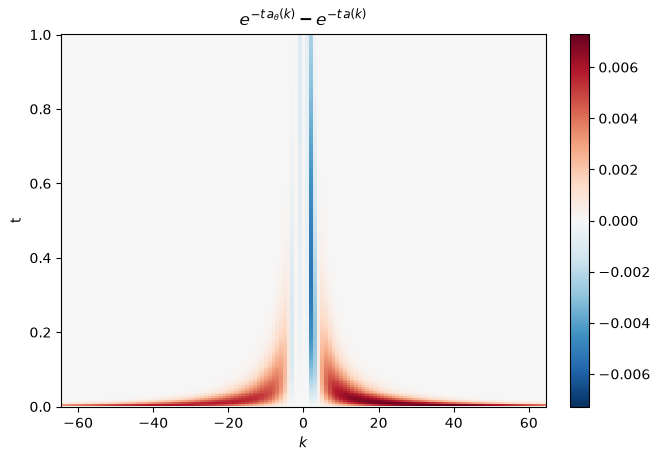

In [58]:
figures.multiplier_figure(modelo, cargado.reference, cargado.results, K=cargado.k_max)

**Simbolo fuera de la ventana.** $a_\theta(k)$ frente a la referencia hasta $|k|=1000$, y $h_\theta(k)=a_\theta(k)/\langle k\rangle^m$ con la banda $(c,C)$.

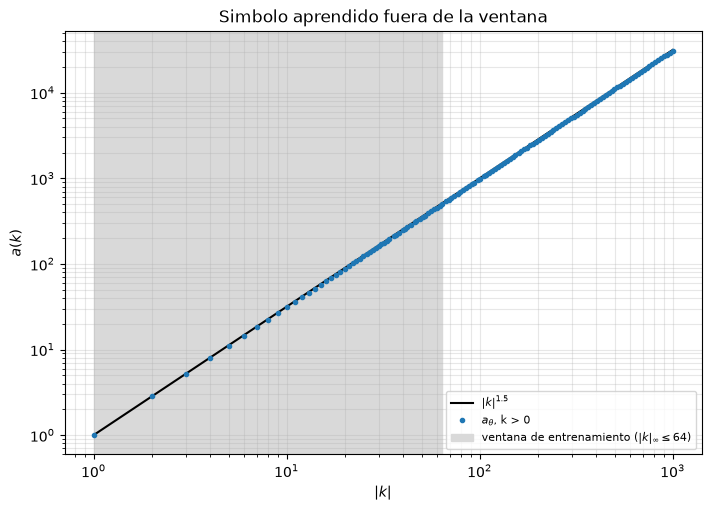

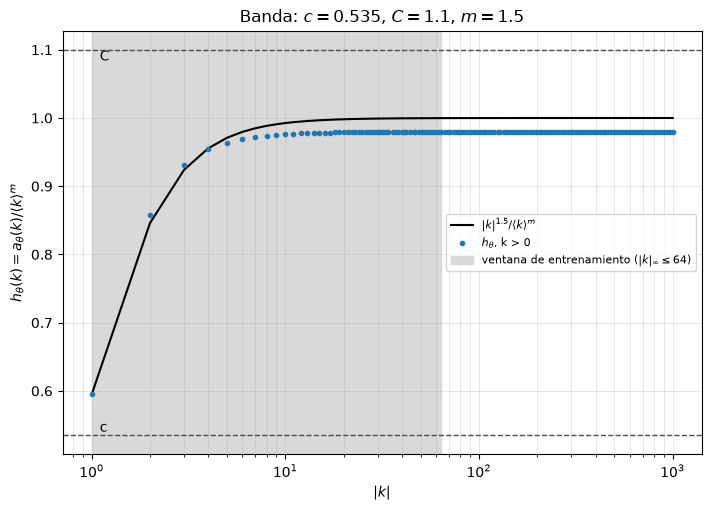

In [59]:
figures.symbol_extrapolation_figure(modelo, cargado.reference, cargado.results, k_window=cargado.k_max)

**Error contra $t$, con extrapolacion.** Error relativo $L^2$ en espacio fisico de las condiciones iniciales de prueba, hasta $t=3$.

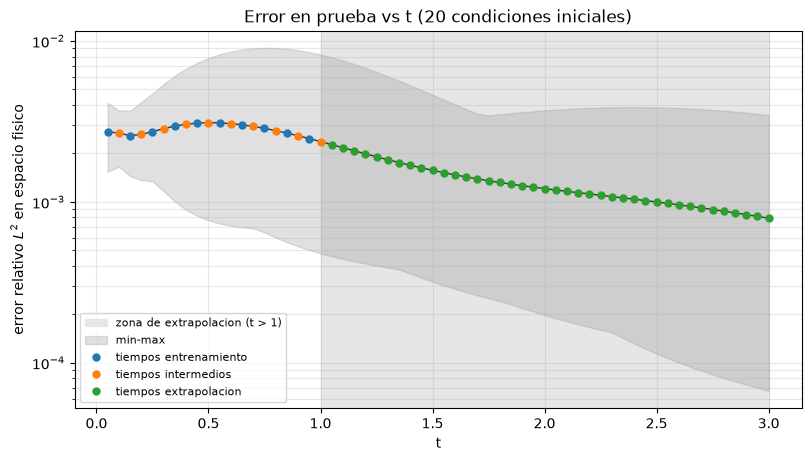

In [60]:
figures.extrapolation_error_figure(modelo, cargado.grf_test, cargado.results)

**Error del simbolo.** $|a_\theta(k)-a(k)|/|a(k)|$ en cada $k$ de entrenamiento y de validacion.

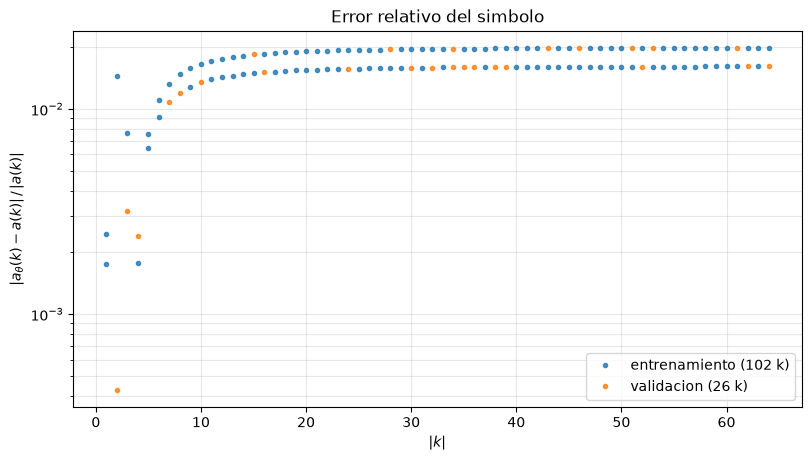

In [61]:
figures.symbol_error_figure(modelo, cargado.reference, cargado.train_data, cargado.val_data, cargado.results)

**Espectro de potencia.** $\mathbb{E}|\hat u(t,k)|^2$ medio de las condiciones iniciales de prueba, por capa de $|k|$, en $t\in\{0.05,0.25,1\}$.

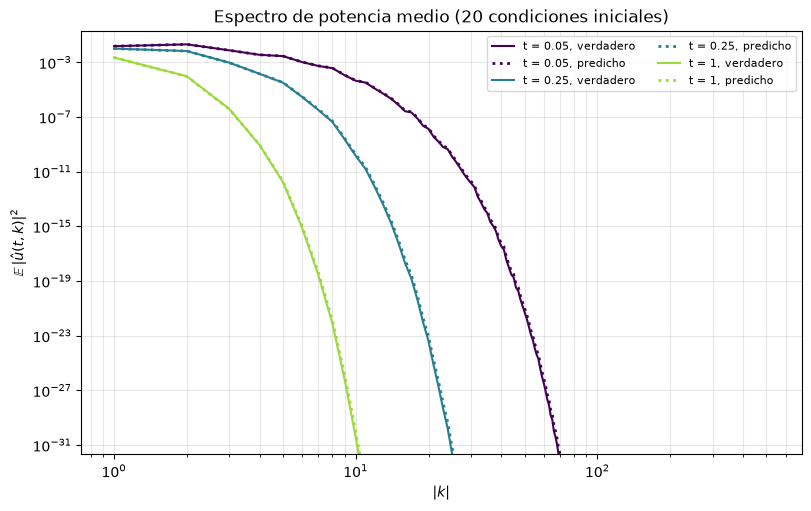

In [62]:
figures.power_spectrum_figure(modelo, cargado.grf_test, cargado.results)

# Resumen

Una fila por $\alpha$: ventana de $k$, $c$, $C$, $\kappa$, configuracion elegida, error relativo de validacion, error en prueba (pares $(k,t)$ y espacio fisico), error relativo medio del simbolo en $|k_i|\le k_{\max}$, peor ratio de la certificacion (en las tres ventanas) y multiindices consistentes. Se guarda en `resumen.csv`.

In [63]:
display(summary_table(experimentos, RESULTS))

,alpha,ventana_k,c,C,kappa,configuracion,val_rel_l2,test_rel_l2,test_rel_l2_fisico,error_simbolo_medio,peor_ratio,multiindices_consistentes
0,0.5,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.756807,1.099933,2.000000,"2x32, dropout OFF, wd=0.0001",0.000371,0.000254,0.000269,0.001027,0.594649,3/3
1,1.0,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.636396,1.099866,2.222222,"3x128, dropout OFF, wd=0",0.001128,0.004992,0.003885,0.004930,0.636159,3/3
2,1.5,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.535143,1.099763,2.642682,"2x128, dropout OFF, wd=0",0.002231,0.003536,0.002813,0.016129,0.653580,3/3


Error en prueba (pares $(k,t)$ y espacio fisico) y peor ratio de la certificacion contra $\alpha$, leidos de `resumen.csv`; la linea discontinua es la cota de la Def. 2.3 (ratio $=1$). Cada grafica en su imagen: `resumen_error_prueba.png` y `resumen_certificacion.png`.

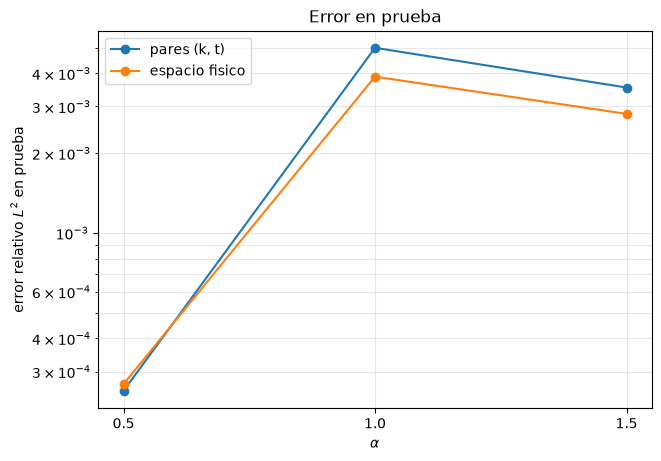

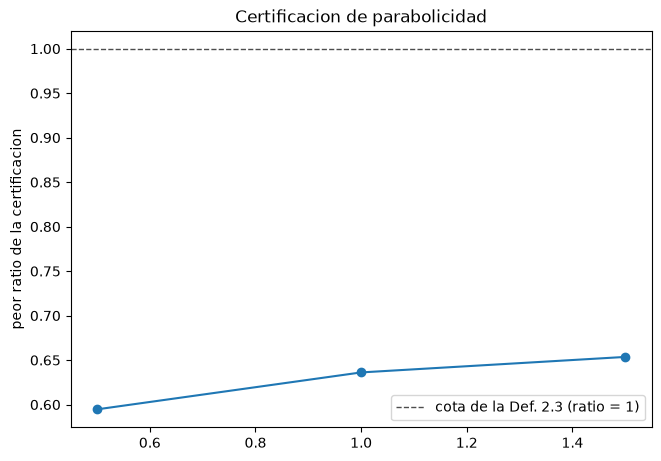

In [64]:
from parabolic_symbol.learning import figures

figures.summary_figure(RESULTS / "resumen.csv", RESULTS)